# Residual PPO for building HVAC control

**The problem.** The NeurIPS 2026 Smart Buildings competition asks for **one** control policy that runs the heating,
ventilation and air conditioning of buildings it has never seen. Every 5 minutes, for 30 days (8,640 steps), it
decides which air handlers run, their supply-air temperature, pressure and recirculation, the hot-water loop, and
each zone's damper and reheat valve.

**The score.** Each step's reward trades comfort (0.6) against energy cost (0.2) and carbon (0.2). The leaderboard
takes `abs(mean(reward))` per scenario, averaged over 30 scenarios (6 buildings × 5 climates). Lower is better; 0 is
perfect.

**Why plain RL is awkward here.**

| obstacle | what we do about it |
|---|---|
| actions are hybrid: on/off switches + continuous setpoints | PPO controls only the continuous part; the on/off switching stays with the PID |
| action and observation sizes differ per building | this notebook trains on **one** building; sharing a policy across buildings is the next step |
| a bad policy can freeze or cook a building for days | **residual** control: the organisers' PID acts, PPO adds a correction of at most ±0.3 |

```
 observation ──► organisers' PID ──► base action ──┐
       │                                           ├─► clip(base + 0.3 · a) ──► simulator ──► reward
       └──────► PPO policy ───────► a ∈ [-1,1]ⁿ ───┘
```

**The data.** Scenario `building_train_8 / atlanta_1` from the official starter kit: one building, 30 days of recorded
Atlanta weather. We train on **days 1–2** and evaluate on **days 3–4**, which the policy never saw.

## Setup (once)

This case study runs the official NeurIPS 2026 Smart Buildings simulator, which is not part of this repo:

```bash
git clone https://github.com/smart-buildings-2026/starter-kit ~/sb-starter-kit
python3.12 -m venv .venv-sb && .venv-sb/bin/pip install -e ~/sb-starter-kit "stable-baselines3>=2.6" jupyter
export SB_KIT=~/sb-starter-kit        # sbrl.py finds the kit here
```

`sbrl.py` (next to this notebook) holds the residual-PID wrapper. The outputs below are from a run on an M4 Pro,
2026-10-25: 200k PPO steps in about 7 minutes on 8 processes.

**Why it is in this repo:** it is a run that does not learn and raises no error. Section 5 shows how we could tell.

In [1]:
import sys, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd()                      # run from notebooks/, where sbrl.py sits
sys.path.insert(0, str(ROOT))
import sbrl
plt.rcParams.update({'figure.dpi': 110})
E, env, meta, spec, pid = sbrl.make_base()
obs, _ = env.reset()
print('observation', obs.shape, '| continuous actions', spec['continuous_action'].shape, '| on/off actions', spec['discrete_action'].shape)
print('zones', len(meta['zone_temp_indices']), '| air handlers', len(meta['ahu_zone_assignments']), '| comfort window', meta['comfort_temp_window'])
pd.DataFrame({'observation field': meta['observation_field_names'][:8], 'value': obs[:8]})

observation (283,) | continuous actions (71,) | on/off actions (4,)
zones 30 | air handlers 3 | comfort window (294.0, 297.0)


,observation field,value
0,VAV_1_reheat_valve_percentage_command,-1.0
1,VAV_1_supply_air_damper_percentage_command,-0.8
2,VAV_1_supply_air_flowrate_setpoint,2.0
3,VAV_1_zone_air_cooling_temperature_setpoint_se...,297.0
4,VAV_1_zone_air_heating_temperature_setpoint_se...,294.0
5,VAV_1_zone_air_temperature_sensor,-0.2
6,VAV_10_reheat_valve_percentage_command,-1.0
7,VAV_10_supply_air_damper_percentage_command,-0.8


## 1. What the baseline does

Run the organisers' best PID (`pid_water`) for two days and look at the reward hour by hour.

PID, days 1-2: |mean reward| = 0.02497  (8s)


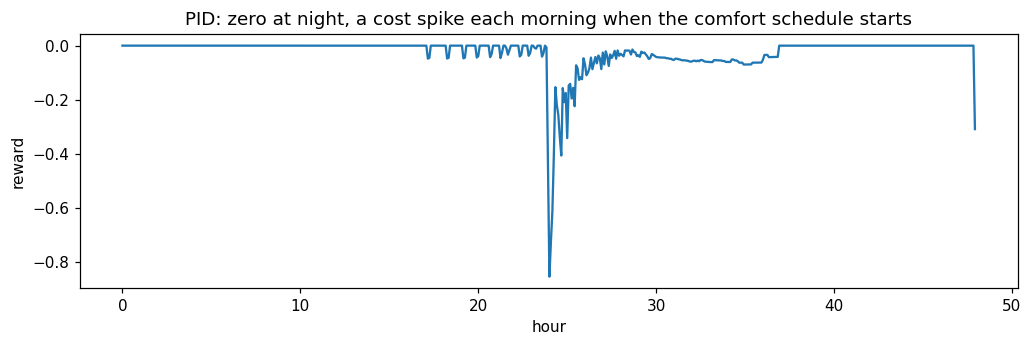

In [2]:
def run(policy_fn, steps=576, warmup=0, seed_env=None):
    e = sbrl.ResidualPID(episode_steps=steps, warmup_steps=warmup)
    o, _ = e.reset(); done = False
    while not done:
        o, r, te, tr, info = e.step(policy_fn(o)); done = te or tr
    return np.array(e.raw)
zero = lambda o: np.zeros(spec['continuous_action'].shape, np.float32)
t = time.time(); r_pid = run(zero); print(f'PID, days 1-2: |mean reward| = {abs(r_pid.mean()):.5f}  ({time.time() - t:.0f}s)')
plt.figure(figsize=(11, 3)); plt.plot(np.arange(len(r_pid)) / 12, r_pid); plt.xlabel('hour'); plt.ylabel('reward')
plt.title('PID: zero at night, a cost spike each morning when the comfort schedule starts'); plt.show()

**Is the simulator deterministic?** Build a fresh environment three times and run the same zero correction.
(A trap we hit: calling `reset()` on the *same* environment does not restore the exact start state, and a second
episode scored −0.02606 instead of −0.02497. Every evaluation below therefore builds a fresh environment.)

In [3]:
reps = [abs(run(zero).mean()) for _ in range(3)]
print('PID |mean reward|, 3 fresh environments:', np.round(reps, 5), f'-> spread {np.ptp(reps):.5f}')

PID |mean reward|, 3 fresh environments: [0.02497 0.02497 0.02497] -> spread 0.00000


## 2. The environment for PPO

`sbrl.ResidualPID` (in `sbrl.py`) wraps the official environment:

* **action** `a ∈ [-1, 1]^71`: added to the PID's continuous action, scaled by 0.3, then clipped;
* **reward**: the official reward × 10 (PPO likes rewards of order 1);
* **episode**: 576 steps = 2 days, then truncated.

A zero action reproduces the PID exactly, so PPO starts from the baseline and only has to learn what to change.

## 3. Train PPO (stable-baselines3)

8 environments in parallel processes, observations normalised on the fly (`VecNormalize`), 200,000 steps.
Checkpoints go to `data/ppo/` every 25,000 steps; if a finished model exists, this cell loads it instead of training.

In [4]:
from stable_baselines3 import PPO
import os
os.environ['PYTHONPATH'] = str(ROOT)          # spawned worker processes must be able to import sbrl
from stable_baselines3.common.vec_env import SubprocVecEnv, DummyVecEnv, VecNormalize
from stable_baselines3.common.callbacks import CheckpointCallback
OUT = ROOT.parent / 'data' / 'smart_buildings_ppo'; OUT.mkdir(parents=True, exist_ok=True)
STEPS = 200_000
if __name__ == '__main__' and not (OUT / 'final.zip').exists():
    venv = VecNormalize(SubprocVecEnv([lambda: sbrl.ResidualPID() for _ in range(8)]), norm_obs=True, norm_reward=False, clip_obs=10)
    model = PPO('MlpPolicy', venv, n_steps=576, batch_size=576, n_epochs=5, learning_rate=3e-4, gamma=0.99,
                ent_coef=0.0, policy_kwargs=dict(net_arch=[128, 128], log_std_init=-1.5), seed=0, verbose=0)
    t = time.time()
    model.learn(STEPS, callback=CheckpointCallback(25_000 // 8, str(OUT), name_prefix='ppo', save_vecnormalize=True))
    venv.save(str(OUT / 'vecnormalize.pkl')); model.save(OUT / 'final'); venv.close()
    print(f'trained {STEPS:,} steps in {(time.time() - t) / 60:.1f} min')
stats = OUT / 'vecnormalize.pkl' if (OUT / 'vecnormalize.pkl').exists() else sorted(OUT.glob('ppo_vecnormalize_*_steps.pkl'), key=lambda p: int(p.stem.split('_')[-2]))[-1]
norm = VecNormalize.load(str(stats), DummyVecEnv([lambda: sbrl.ResidualPID()])); norm.training = False
model = sbrl.load_ppo(OUT / 'final.zip', norm)      # PPO.load is broken under torch 2.14.1; see sbrl.load_ppo
print('normalisation stats from', stats.name)
ppo = lambda o: model.predict(norm.normalize_obs(o[None]), deterministic=True)[0][0]
print('policy loaded; log_std (exploration noise) mean', float(model.policy.log_std.mean()))

normalisation stats from vecnormalize.pkl
policy loaded; log_std (exploration noise) mean -1.5063111782073975


/var/folders/gf/py2bkq010_gd3k4m93w4_dgm0000gn/T/ipykernel_55053/3535501444.py:21: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print('policy loaded; log_std (exploration noise) mean', float(model.policy.log_std.mean()))


## 4. Did it learn anything? Held-out days

Days 3–4: the PID drives alone through days 1–2 (warm-up), then either keeps driving (baseline) or gets PPO's
correction. Fresh environment per run; three repeats each as a determinism check.

In [5]:
rows = []
for name, fn in (('PID', zero), ('PID + PPO residual', ppo)):
    for split, warm in (('train days 1-2', 0), ('held-out days 3-4', 576)):
        for k in range(3):
            r = run(fn, warmup=warm); rows.append(dict(policy=name, split=split, rep=k, score=abs(r.mean())))
R = pd.DataFrame(rows)
S = R.groupby(['split', 'policy']).score.agg(['mean', 'std']).round(5); print(S.to_string())

                                         mean  std
split             policy                          
held-out days 3-4 PID                 0.03006  0.0
                  PID + PPO residual  0.03020  0.0
train days 1-2    PID                 0.02497  0.0
                  PID + PPO residual  0.02521  0.0


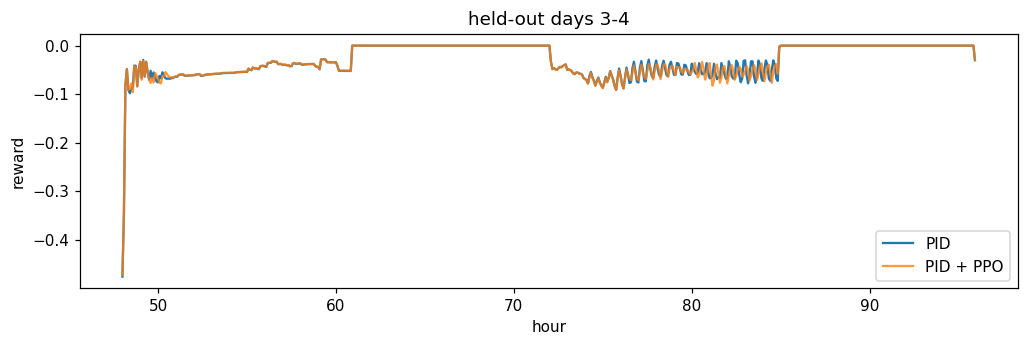

size of the learned correction at the start of an episode: mean |a| = 0.113 (max 1)


In [6]:
r_a, r_b = run(zero, warmup=576), run(ppo, warmup=576)
plt.figure(figsize=(11, 3)); plt.plot(np.arange(576) / 12 + 48, r_a, label='PID'); plt.plot(np.arange(576) / 12 + 48, r_b, label='PID + PPO', alpha=.8)
plt.xlabel('hour'); plt.ylabel('reward'); plt.legend(); plt.title('held-out days 3-4'); plt.show()
a = np.stack([ppo(o) for o in [sbrl.ResidualPID().reset()[0]]])
print('size of the learned correction at the start of an episode: mean |a| =', float(np.abs(a).mean()).__round__(3), '(max 1)')

## 5. Reading the result

**What we measured** (|mean reward|, lower is better):

| split | PID | PID + PPO residual |
|---|---|---|
| train days 1–2 | 0.02497 | 0.02521 (+1.0%, worse) |
| held-out days 3–4 | 0.03006 | 0.03020 (+0.5%, worse) |

**A null.** 200k steps (43 policy updates, 7 minutes on 8 processes) did not teach PPO an improvement: its
exploration noise stayed at its initial value (log_std −1.506 vs −1.5), and its correction (mean |a| ≈ 0.11) is a
small perturbation that costs a little. Two untested reasons: 43 updates is very few for a 71-dimensional action, and
the reward is zero for most of each day, so most steps carry no signal.

* Compare the held-out rows: they show whether a learned rule carries to new weather.
* The training workers reuse their environments, so after the first episode their "days 1–2" start from a slightly
  different state (`reset()` is not exact). Harmless for learning; it is why evaluation never reuses one.
* One building, one climate, 200k steps (about 35 days of simulated time). The competition scores unseen buildings.

## 6. Where to take it

1. **Longer training and the full 30 days**: the evaluator scores all 8,640 steps.
2. **All 30 scenarios**: one environment per scenario in the vector env; this needs a policy that does not depend on
   the action size, e.g. one small network applied to every zone (shared weights) plus one per air handler.
3. **Give PPO the on/off switches**: the public notebooks found the biggest gain there (keep cooling air handlers
   running instead of switching them 50–107 times a day).
4. **Compare with black-box search**: tune a handful of PID constants with CMA-ES on the same split; it is the honest
   baseline for any RL claim.

## Check yourself

1. Why does a zero residual make the first PPO update safe?
2. Why train on days 1–2 and test on days 3–4 rather than test on days 1–2 again?
3. The reward is zero at night. What does that imply for the discount factor γ and the morning spike?